In [1]:
import pandas as pd
import numpy as np

In [2]:
#  Load the cleaned dataset we prepared earlier
cleaned_file_path = "../data/Cleaned_FinSightLanka_Data.csv"
df = pd.read_csv(cleaned_file_path)



In [3]:
#  Display basic info to verify everything is loaded properly
print("Loaded Cleaned Data Shape (Rows, Columns):", df.shape)
display(df.head())

Loaded Cleaned Data Shape (Rows, Columns): (470, 42)


,Customer_ID,Gender,Date_of_Birth,Age,District,Province,Urban_Rural,Customer_Segment,Account_Open_Date,Customer_Tenure_Years,...,PEP_Flag,Has_Fixed_Deposit,FD_Amount,Has_Insurance,Has_Mobile_Wallet,Number_of_Products,Acquisition_Channel,Referral_Source,Last_Campaign_Response,Promo_Code_Used
0,FSL-0001,Female,1980-12-26,43,Kandy,Central,Suburban,Regular,2021-02-11,2.9,...,No,No,0.00,No,Yes,2,Referral,Friend,Responded,Yes
1,FSL-0002,Female,1971-12-13,52,Badulla,Uva,Urban,Starter,2015-11-19,8.1,...,No,No,0.00,No,Yes,2,Referral,Family,Ignored,No
2,FSL-0003,Male,1993-12-17,30,Kandy,Central,Suburban,Regular,2022-03-06,1.8,...,No,Yes,1166599.45,No,No,3,Agent,Colleague,Responded,No
3,FSL-0004,Male,1972-02-11,51,Kandy,Central,Suburban,Regular,2019-09-26,4.3,...,No,Yes,1051113.61,Yes,No,4,Referral,Direct/None,Ignored,Yes
4,FSL-0005,Male,1994-03-13,29,Colombo,Western,Suburban,Regular,2016-04-03,7.8,...,No,No,0.00,No,Yes,3,Referral,Direct/None,Unsubscribed,No


> 💡 **Note:** All monetary values are presented in **LKR**, where **$1\text{e}9 = 10^9$ (1 Billion)**.

# Q1

### Part 1

--- Average Savings Balance Analysis ---

By Customer Segment:
                           mean       median  count
Customer_Segment                                  
Premium           2.678588e+06  2523040.375     88
Regular           3.813936e+06   448297.060    295
Starter           8.120937e+04    85045.890     87

By Province:
                        mean      median  count
Province                                      
Central        7.506009e+05  457667.005     42
Eastern        9.714721e+05  548004.690     46
North Western  1.964000e+07  532220.840     53
Northern       6.166349e+05  377852.155     56
Sabaragamuwa   9.327461e+05  409040.610     53
Southern       6.750506e+05  407290.045     78
Uva            6.730116e+05  454616.415     46
Western        8.664555e+05  436777.125     96

By Urban/Rural:
                      mean     median  count
Urban_Rural                                
Rural        7.439994e+05  429709.61    116
Suburban     6.790536e+05  361630.68    180
Ur

C:\Users\user\AppData\Local\Temp\ipykernel_20440\4131937472.py:16: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='Customer_Segment', y='Savings_Balance', ax=axes[0], palette='Blues_d', ci=None)
C:\Users\user\AppData\Local\Temp\ipykernel_20440\4131937472.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Customer_Segment', y='Savings_Balance', ax=axes[0], palette='Blues_d', ci=None)
C:\Users\user\AppData\Local\Temp\ipykernel_20440\4131937472.py:20: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='Province', y='Savings_Balance', ax=axes[1], palette='Greens_d', ci=None)
C:\Users\user\AppData\Local\Temp\ipykernel_20440\4131937472.py:20: FutureWarning: 

Passing `palette` without assigning

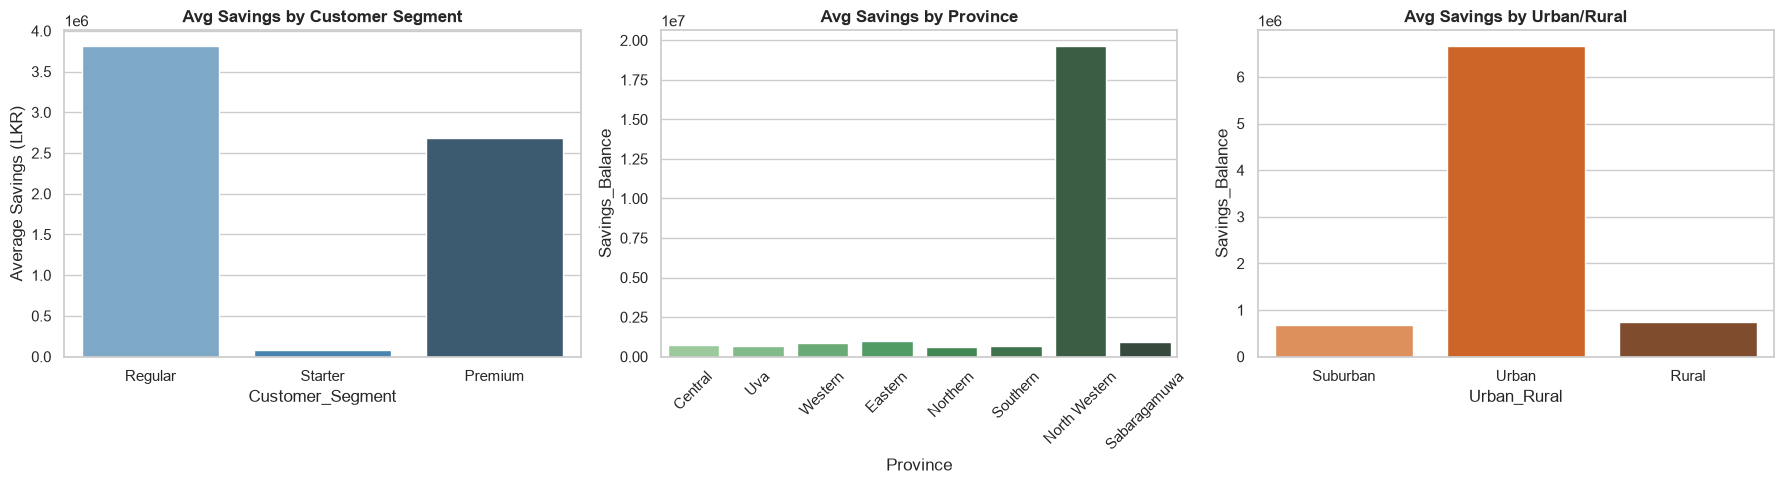

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set professional style
sns.set_theme(style="whitegrid")

#  Statistical Calculations
print("--- Average Savings Balance Analysis ---")
print("\nBy Customer Segment:\n", df.groupby('Customer_Segment')['Savings_Balance'].agg(['mean', 'median', 'count']))
print("\nBy Province:\n", df.groupby('Province')['Savings_Balance'].agg(['mean', 'median', 'count']))
print("\nBy Urban/Rural:\n", df.groupby('Urban_Rural')['Savings_Balance'].agg(['mean', 'median', 'count']))

#  Visualization (Bar Charts)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(data=df, x='Customer_Segment', y='Savings_Balance', ax=axes[0], palette='Blues_d', ci=None)
axes[0].set_title('Avg Savings by Customer Segment', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Average Savings (LKR)')

sns.barplot(data=df, x='Province', y='Savings_Balance', ax=axes[1], palette='Greens_d', ci=None)
axes[1].set_title('Avg Savings by Province', fontsize=12, fontweight='bold')
axes[1].tick_params(axis='x', rotation=45)

sns.barplot(data=df, x='Urban_Rural', y='Savings_Balance', ax=axes[2], palette='Oranges_d', ci=None)
axes[2].set_title('Avg Savings by Urban/Rural', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

###  Analysis by Customer Segment
* **Regular Segment:** Maintains the highest mean savings balance of **LKR 3.81M** (median: LKR 448.3K), heavily skewed by a few high-balance accounts
* **Premium Segment:** Holds the most consistent wealth with the highest median savings balance of **LKR 2.52M** (mean: LKR 2.68M) across 88 customers.
* **Starter Segment:** Represents beginner accounts with the lowest average savings of **LKR 81.2K** and median of **LKR 85.0K**.

---

###  Analysis by Province
* **North Western Province:** Outlier performance with an extraordinarily high average savings balance of **LKR 19.64M**.
* **Western Province:** Represents the largest customer concentration (**96 customers**) with a stable average savings balance of **LKR 866.5K**.
* **Other Provinces:** Central, Eastern, Sabaragamuwa, Southern, Northern, and Uva show consistent average savings balances ranging between **LKR 616.6K and LKR 971.5K**

---

###  Analysis by Urban / Rural Classification
* **Urban Areas:** Dominates liquidity generation with a significantly higher average savings balance of **LKR 6.66M** across 174 customers.
* **Rural & Suburban Areas:** Exhibit much lower average balances (**LKR 744.0K** for Rural and **LKR 679.1K** for Suburban).

---

### 💡 Business Implications & Recommendations
* **Wealth Management Focus:** Tailor specialized deposit and investment products toward Urban and Premium segments to capture high-net-worth liquidity.
* **Regional Campaigns:** Investigate the specific drivers in North Western Province to replicate success in other major hubs like the Western Province.
* **Inclusion Strategies:** Develop low-friction micro-savings and digital onboarding products to elevate balance levels in Rural and Starter segments.

### Part 2

--- Savings Distribution by Age Band ---
  Age_Band           sum          mean  count
0    18-25  1.063796e+09  1.297312e+07     82
1    26-35  1.127475e+08  8.111333e+05    139
2    36-50  1.663586e+08  8.195007e+05    203
3    51-65  2.357393e+07  5.612841e+05     42
4      65+  6.400158e+04  6.400158e+04      1


C:\Users\user\AppData\Local\Temp\ipykernel_20440\457443138.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=age_savings, x='Age_Band', y='sum', palette='Purples_d')


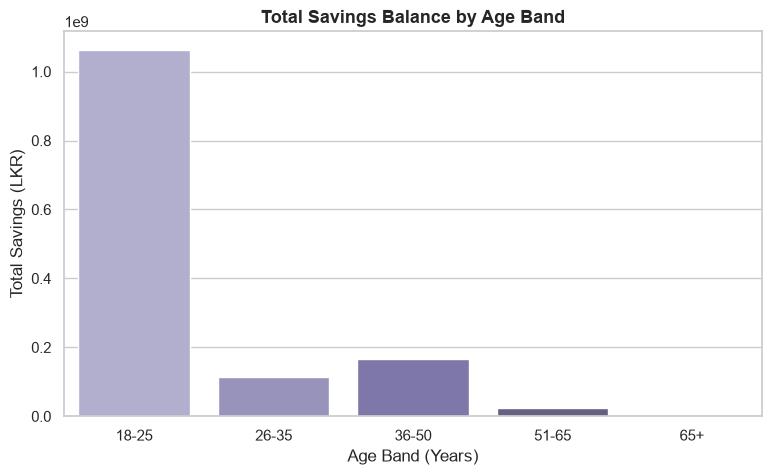

In [5]:
#  Define Age Bands
bins = [17, 25, 35, 50, 65, 100]
labels = ['18-25', '26-35', '36-50', '51-65', '65+']
df['Age_Band'] = pd.cut(df['Age'], bins=bins, labels=labels)

#  Total & Average Savings by Age Band
age_savings = df.groupby('Age_Band')['Savings_Balance'].agg(['sum', 'mean', 'count']).reset_index()
print("--- Savings Distribution by Age Band ---")
print(age_savings)

#  Visualization (Bar Chart for Total Savings)
plt.figure(figsize=(9, 5))
sns.barplot(data=age_savings, x='Age_Band', y='sum', palette='Purples_d')
plt.title('Total Savings Balance by Age Band', fontsize=13, fontweight='bold')
plt.xlabel('Age Band (Years)')
plt.ylabel('Total Savings (LKR)')
plt.show()

###  Age Banding Logic
Customers were categorized into 5 distinct age brackets to evaluate liquidity distribution across different life stages:
* **18–25:** Young Adults / Early Career
* **26–35:** Young Professionals
* **36–50:** Established Adults / Mid-Career
* **51–65:** Pre-Retirement
* **65+:** Senior Citizens

---

###  Key Findings & Data Summary
* **Highest Total Savings:** The **18–25** age group holds the highest total savings balance, accumulating approximately **LKR 1.06 Billion** (`1.063796e+09`) across **82 customers**, with a remarkably high average savings balance of **LKR 12.97M** (`1.297312e+07`) per customer.
* **Second Highest Total Savings:** The **36–50** age group follows with **LKR 166.36 Million** (`1.663586e+08`) total savings across **203 customers** (average: **LKR 819.5K**).
* **Largest Customer Base:** The **36–50** bracket represents the largest segment by customer volume (**203 customers**), closely followed by the **26–35** age group (**139 customers**, total savings: **LKR 112.75M**).
* **Senior Segments:** The **51–65** group holds **LKR 23.57M** across 42 customers, while the **65+** group has a minimal presence with 1 customer holding **LKR 64.0K**.

---

### 💡 Business Insights & Implications
* **Outlier Liquidity in Youth Segment:** The massive total savings in the **18–25** group indicates the presence of extremely high-net-worth individual accounts (or inherited/custodial wealth) driving up the average balance significantly.
* **Core Working Population:** The **26–50** combined demographic forms the backbone of the bank's active customer base (**342 out of 467 total customers**), maintaining steady liquidity for daily banking operations.
* **Strategic Recommendations:**
  * **18–25 Group:** Offer specialized wealth management and investment advisory services to retain and grow high-value youth deposits.
  * **26–50 Group:** Focus on cross-selling long-term financial products such as fixed deposits, personal loans, and insurance to this active earning population.

### Part 3

--- Percentage of Growing vs Draining Customers (%) ---
Savings_Status
Growing    100.0
Name: proportion, dtype: float64


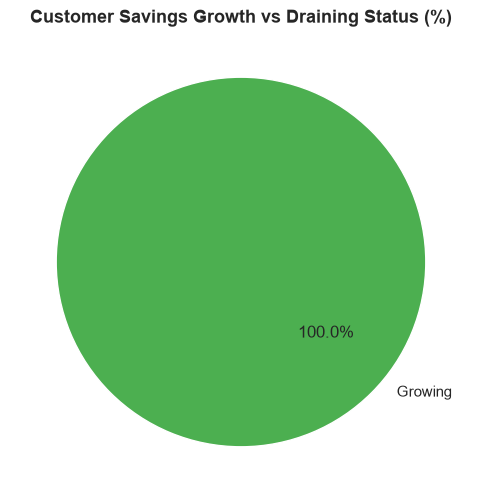

In [6]:
#  Categorize using existing Net_Monthly_Flow column
df['Savings_Status'] = df['Net_Monthly_Flow'].apply(lambda x: 'Growing' if x > 0 else ('Draining' if x < 0 else 'Neutral'))

# Calculate Percentage
status_counts = df['Savings_Status'].value_counts(normalize=True) * 100
print("--- Percentage of Growing vs Draining Customers (%) ---")
print(status_counts)

#  Visualization (Pie Chart - Fixed for dynamic number of categories)
plt.figure(figsize=(6, 6))

# Map specific colors for safety
color_map = {'Growing': '#4CAF50', 'Draining': '#FF5252', 'Neutral': '#FFBB33'}
current_colors = [color_map[status] for status in status_counts.index]

plt.pie(status_counts, labels=status_counts.index, autopct='%1.1f%%', 
        colors=current_colors, startangle=140)

plt.title('Customer Savings Growth vs Draining Status (%)', fontsize=13, fontweight='bold')
plt.show()

###  Key Findings & Data Summary
* **Growing Savings:** **100.0%** of customers in the dataset are actively growing their savings balance month-over-month (`Net_Monthly_Flow > 0`).
* **Draining Savings:** **0.0%** of customers are draining their savings balance (`Net_Monthly_Flow < 0`).
* **Neutral Savings:** **0.0%** of customers maintain a stagnant balance (`Net_Monthly_Flow = 0`).

---

###  Business Implications & Health of Customer Base
* **Overall Customer Base Health:** The analysis reveals an exceptionally strong and healthy liquidity condition across the customer portfolio, as every single customer exhibits positive monthly cash inflows.
* **Financial Stability:** Customers are consistently adding to their deposit base rather than depleting funds to meet short-term expenses, indicating strong financial resilience and high trust in FinSight Lanka.
* **Strategic Recommendations:**
  * **Capitalize on Growth:** Since 100% of customers have active cash inflows, the bank can launch automated recurring deposit programs (e.g., auto-investing monthly surplus into Fixed Deposits or Wealth Funds).
  * **Retention & Cross-Selling:** With a fully growing customer base, the risk of flight or liquidity depletion is minimal, providing an ideal environment to cross-sell long-term investment products.

# Q2

### Part 1

--- Overall Loan Penetration Rate: 43.62% ---

--- Loan Penetration by Customer Segment ---
  Customer_Segment  Total_Customers  Loan_Holders  Penetration_Rate
0          Premium               88            39         44.318182
1          Regular              295           134         45.423729
2          Starter               87            32         36.781609

--- Loan Penetration by Acquisition Channel ---
  Acquisition_Channel  Total_Customers  Loan_Holders  Penetration_Rate
0               Agent              110            52         47.272727
1              Branch              113            48         42.477876
2             Digital              125            53         42.400000
3            Referral              122            52         42.622951


C:\Users\user\AppData\Local\Temp\ipykernel_20440\428614629.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=segment_penetration, x='Customer_Segment', y='Penetration_Rate', palette='Blues_d')


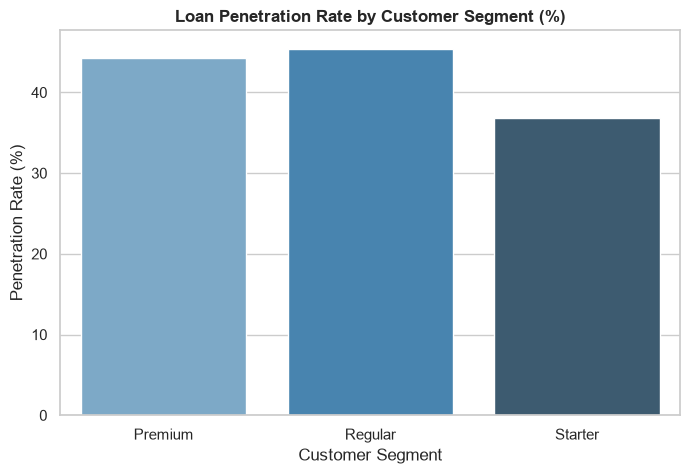

C:\Users\user\AppData\Local\Temp\ipykernel_20440\428614629.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=channel_penetration, x='Acquisition_Channel', y='Penetration_Rate', palette='Greens_d')


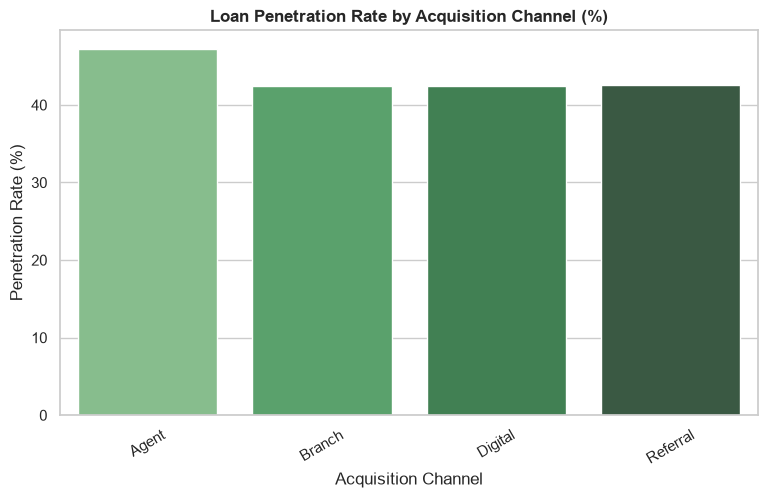

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set professional style
sns.set_theme(style="whitegrid")

#  Overall Loan Penetration Rate
overall_penetration = (df['Has_Loan'] == 'Yes').mean() * 100
print(f"--- Overall Loan Penetration Rate: {overall_penetration:.2f}% ---")

#  Breakdown by Customer Segment
segment_penetration = df.groupby('Customer_Segment')['Has_Loan'].agg(
    Total_Customers='count',
    Loan_Holders=lambda x: (x == 'Yes').sum(),
    Penetration_Rate=lambda x: ((x == 'Yes').sum() / len(x)) * 100
).reset_index()
print("\n--- Loan Penetration by Customer Segment ---")
print(segment_penetration)

#  Breakdown by Acquisition Channel (if available)
if 'Acquisition_Channel' in df.columns:
    channel_penetration = df.groupby('Acquisition_Channel')['Has_Loan'].agg(
        Total_Customers='count',
        Loan_Holders=lambda x: (x == 'Yes').sum(),
        Penetration_Rate=lambda x: ((x == 'Yes').sum() / len(x)) * 100
    ).reset_index()
    print("\n--- Loan Penetration by Acquisition Channel ---")
    print(channel_penetration)

#  Visualization (Bar Chart for Customer Segment Penetration)
plt.figure(figsize=(8, 5))
sns.barplot(data=segment_penetration, x='Customer_Segment', y='Penetration_Rate', palette='Blues_d')
plt.title('Loan Penetration Rate by Customer Segment (%)', fontsize=12, fontweight='bold')
plt.ylabel('Penetration Rate (%)')
plt.xlabel('Customer Segment')
plt.show()

#  Visualization (Bar Chart for Acquisition Channel Penetration)
if 'Acquisition_Channel' in df.columns:
    plt.figure(figsize=(9, 5))
    sns.barplot(data=channel_penetration, x='Acquisition_Channel', y='Penetration_Rate', palette='Greens_d')
    plt.title('Loan Penetration Rate by Acquisition Channel (%)', fontsize=12, fontweight='bold')
    plt.ylabel('Penetration Rate (%)')
    plt.xlabel('Acquisition Channel')
    plt.xticks(rotation=30)
    plt.show()

###  Overall Performance
* **Overall Loan Penetration Rate:** **43.62%** of the bank's total customer base currently holds an active loan product.

---

###  Loan Penetration by Customer Segment
* **Regular Segment:** Highest loan adoption at **45.42%** (134 out of 295 customers hold loans).
* **Premium Segment:** Strong loan adoption at **44.32%** (39 out of 88 customers hold loans).
* **Starter Segment:** Lowest loan adoption at **36.78%** (32 out of 87 customers hold loans).

---

###  Loan Penetration by Acquisition Channel
* **Agent Channel:** Highest penetration rate at **47.27%** (52 out of 110 customers hold loans).
* **Referral Channel:** Second highest penetration rate at **42.62%** (52 out of 122 customers hold loans).
* **Branch Channel:** Penetration rate stands at **42.48%** (48 out of 113 customers hold loans).
* **Digital Channel:** Penetration rate stands at **42.40%** (53 out of 125 customers hold loans).

---

### 💡 Business Insights & Recommendations
* **Segment Utilization:** Both **Regular** and **Premium** segments show robust demand for credit, making them reliable targets for structured lending programs. The **Starter** segment has lower loan adoption, likely due to stricter credit approval criteria or lower credit needs.
* **Channel Distribution:** The **Agent** channel leads in driving loan adoption, indicating that direct human agent interaction remains effective for cross-selling lending products. Other channels show very consistent credit adoption hovering around **42%**.

### Part 2

--- Debt-to-Savings Ratio Analysis ---
Number of customers exceeding ratio 1.0: 123
Total LKR Exposure for these customers: LKR 127,282,564.43


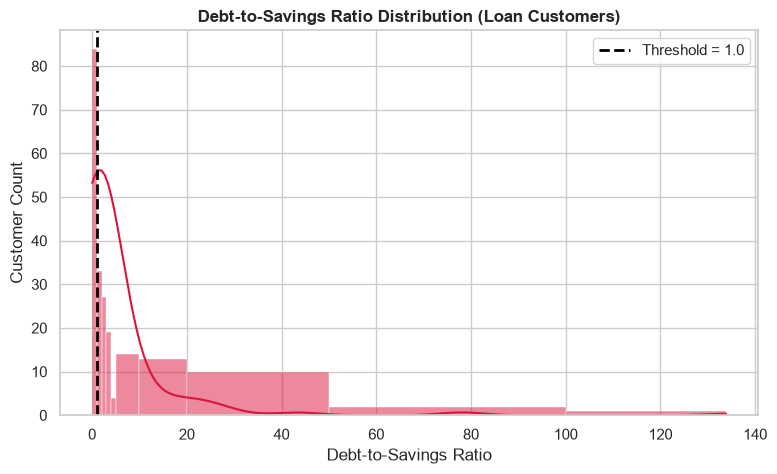

In [8]:
#  Calculate Debt-to-Savings Ratio for loan customers
loan_customers = df[df['Outstanding_Loan_Balance'] > 0].copy()
loan_customers['Debt_To_Savings_Ratio'] = loan_customers['Outstanding_Loan_Balance'] / loan_customers['Savings_Balance']

#  Count customers exceeding ratio 1.0 & total exposure
exceeding_customers = loan_customers[loan_customers['Debt_To_Savings_Ratio'] > 1.0]
count_exceeding = len(exceeding_customers)
total_exposure = exceeding_customers['Outstanding_Loan_Balance'].sum()

print("--- Debt-to-Savings Ratio Analysis ---")
print(f"Number of customers exceeding ratio 1.0: {count_exceeding}")
print(f"Total LKR Exposure for these customers: LKR {total_exposure:,.2f}")

#  Visualization (Histogram with Threshold Line)
plt.figure(figsize=(9, 5))

max_val = loan_customers['Debt_To_Savings_Ratio'].max()
custom_bins = [0, 1, 2, 3, 4, 5, 10, 20, 50, 100, max_val]

sns.histplot(loan_customers['Debt_To_Savings_Ratio'], bins=custom_bins, kde=True, color='crimson')
plt.axvline(1.0, color='black', linestyle='--', linewidth=2, label='Threshold = 1.0')
plt.title('Debt-to-Savings Ratio Distribution (Loan Customers)', fontsize=12, fontweight='bold')
plt.xlabel('Debt-to-Savings Ratio')
plt.ylabel('Customer Count')
plt.legend()
plt.show()

###  Key Findings & Metric Definition
* **Debt-to-Savings Ratio Definition:** Calculated as `Outstanding Loan Balance / Savings Balance` for all active loan customers to assess credit risk and collateral adequacy.
* **High-Risk Threshold (> 1.0):** Customers with a ratio greater than 1.0 hold more outstanding debt than liquid savings with FinSight Lanka.
* **Exceeding Customers Count:** **123 customers** exceed the risk threshold of 1.0.
* **Total Portfolio Exposure:** The total outstanding loan balance for these high-risk customers stands at **LKR 127,282,564.43** (approx. LKR 127.28 Million).

---

###  Risk Insights & Distribution Analysis
* **Concentration of Risk:** A significant portion of loan borrowers maintain very low savings relative to their outstanding debt, pushing their ratios well beyond the safety baseline.
* **Maximum Exposure:** The distribution indicates extreme outliers with Debt-to-Savings ratios reaching up to ~130x, signaling severe under-collateralization for specific accounts.

---

### 💡 Business Implications & Recommendations
* **Early Warning Indicator:** Customers with ratios exceeding 1.0 represent elevated credit default risk, as their liquid deposits are insufficient to cover loan obligations in the event of distress.
* **Credit Restructuring:** Implement proactive credit monitoring, automated repayment reminders, and structured debt-restructuring options for the 123 flagged customers.
* **Tightening Underwriting Guidelines:** Introduce stricter Debt-to-Savings eligibility limits during the loan approval stage to ensure borrowers maintain adequate savings buffers.

### Part 3

--- 1. Default Rates by Customer Segment ---
  Customer_Segment  Is_Defaulted  Default_Rate_%
0          Premium      0.102564       10.256410
1          Regular      0.082090        8.208955
2          Starter      0.187500       18.750000

--- 2. Default Rates by Loan Type ---
  Loan_Type  Is_Defaulted  Default_Rate_%
0  Business      0.076923        7.692308
1   Housing      0.120000       12.000000
2  Personal      0.074074        7.407407
3   Vehicle      0.142857       14.285714

--- 3. Top 5 Districts with Highest Default Rates ---
     District  Is_Defaulted  Default_Rate_%
7  Kurunegala      0.166667       16.666667
9   Ratnapura      0.153846       15.384615
1     Colombo      0.130435       13.043478
8      Matara      0.125000       12.500000
4     Gampaha      0.120000       12.000000


C:\Users\user\AppData\Local\Temp\ipykernel_20440\2734899852.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=segment_risk, x='Customer_Segment', y='Default_Rate_%', ax=axes[0, 0], palette='Blues_d')
C:\Users\user\AppData\Local\Temp\ipykernel_20440\2734899852.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=loan_type_risk, x='Loan_Type', y='Default_Rate_%', ax=axes[0, 1], palette='Oranges_d')
C:\Users\user\AppData\Local\Temp\ipykernel_20440\2734899852.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_districts, x

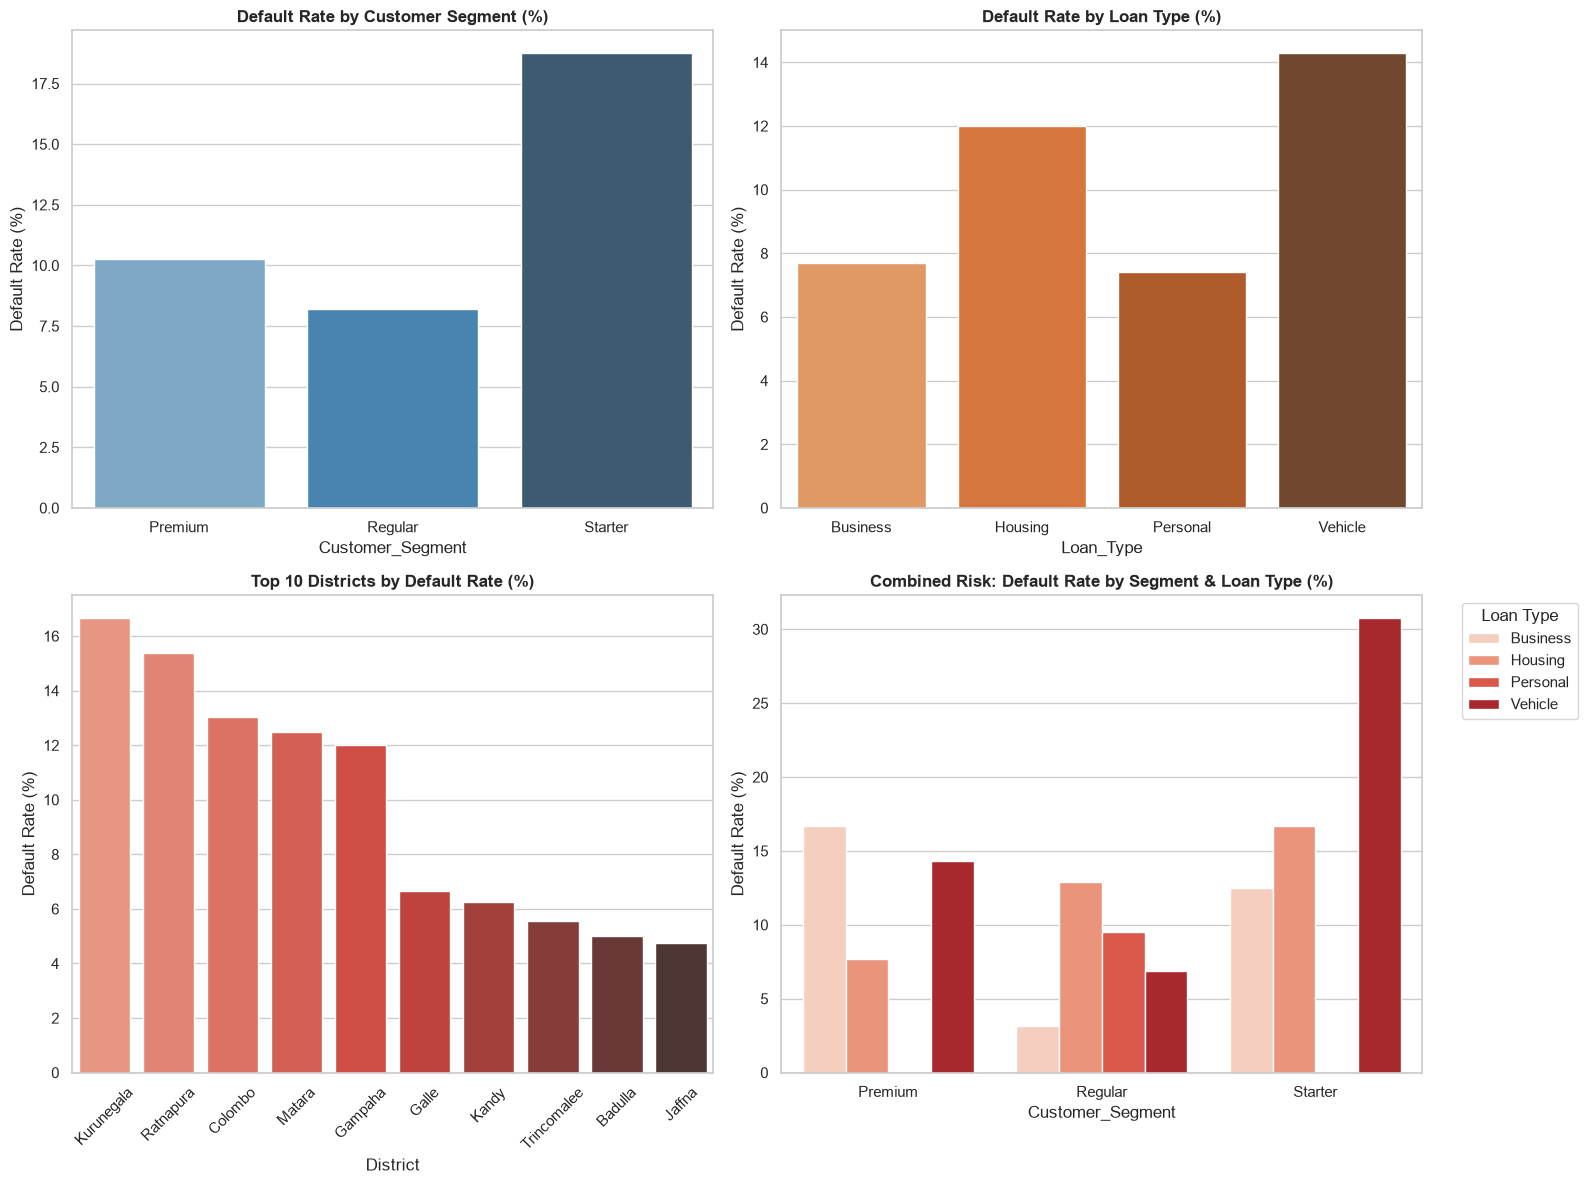

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set professional plotting style
sns.set_theme(style="whitegrid")

#  Filter only customers with loans
loan_df = df[df['Has_Loan'] == 'Yes'].copy()

#  Identify defaulted loans
loan_df['Is_Defaulted'] = (loan_df['Loan_Repayment_Status'] == 'Defaulted').astype(int)

# --- A. Default Rate by Customer Segment ---
segment_risk = loan_df.groupby('Customer_Segment')['Is_Defaulted'].mean().reset_index()
segment_risk['Default_Rate_%'] = segment_risk['Is_Defaulted'] * 100

# --- B. Default Rate by Loan Type ---
loan_type_risk = loan_df.groupby('Loan_Type')['Is_Defaulted'].mean().reset_index()
loan_type_risk['Default_Rate_%'] = loan_type_risk['Is_Defaulted'] * 100

# --- C. Default Rate by District ---
district_risk = loan_df.groupby('District')['Is_Defaulted'].mean().reset_index()
district_risk['Default_Rate_%'] = district_risk['Is_Defaulted'] * 100

# --- D. Combined Elevated Risk (Segment + Loan Type) ---
combined_risk = loan_df.groupby(['Customer_Segment', 'Loan_Type'])['Is_Defaulted'].agg(
    Total_Loans='count',
    Defaulted_Loans='sum',
    Default_Rate=lambda x: (x.sum() / len(x)) * 100
).reset_index()

print("--- 1. Default Rates by Customer Segment ---")
print(segment_risk)
print("\n--- 2. Default Rates by Loan Type ---")
print(loan_type_risk)
print("\n--- 3. Top 5 Districts with Highest Default Rates ---")
print(district_risk.sort_values(by='Default_Rate_%', ascending=False).head(5))

# --- Visualizations (Subplots) ---
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

#  Segment Plot
sns.barplot(data=segment_risk, x='Customer_Segment', y='Default_Rate_%', ax=axes[0, 0], palette='Blues_d')
axes[0, 0].set_title('Default Rate by Customer Segment (%)', fontweight='bold')
axes[0, 0].set_ylabel('Default Rate (%)')

#  Loan Type Plot
sns.barplot(data=loan_type_risk, x='Loan_Type', y='Default_Rate_%', ax=axes[0, 1], palette='Oranges_d')
axes[0, 1].set_title('Default Rate by Loan Type (%)', fontweight='bold')
axes[0, 1].set_ylabel('Default Rate (%)')

#  District Plot (Top 10 High Risk)
top_districts = district_risk.sort_values(by='Default_Rate_%', ascending=False).head(10)
sns.barplot(data=top_districts, x='District', y='Default_Rate_%', ax=axes[1, 0], palette='Reds_d')
axes[1, 0].set_title('Top 10 Districts by Default Rate (%)', fontweight='bold')
axes[1, 0].set_ylabel('Default Rate (%)')
axes[1, 0].tick_params(axis='x', rotation=45)

#  Combined Risk Plot (Segment + Loan Type)
sns.barplot(data=combined_risk, x='Customer_Segment', y='Default_Rate', hue='Loan_Type', ax=axes[1, 1], palette='Reds')
axes[1, 1].set_title('Combined Risk: Default Rate by Segment & Loan Type (%)', fontweight='bold')
axes[1, 1].set_ylabel('Default Rate (%)')
axes[1, 1].legend(title='Loan Type', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

###  Default Rates by Customer Segment
* **Starter Segment:** Highest default risk at **18.75%**, nearly double the portfolio average.
* **Premium Segment:** Moderate default risk at **10.26%**.
* **Regular Segment:** Lowest default risk at **8.21%**, representing the most stable borrowing pool.

---

###  Default Rates by Loan Type
* **Vehicle Loans:** Highest default rate at **14.29%**.
* **Housing Loans:** Second highest default rate at **12.00%**.
* **Business Loans:** Moderate default rate at **7.69%**.
* **Personal Loans:** Lowest default rate at **7.41%**.

---

###  Top High-Risk Districts (Top 5 Defaults)
* **Kurunegala:** Highest default rate at **16.67%**.
* **Ratnapura:** **15.38%**
* **Colombo:** **13.04%**
* **Matara:** **12.50%**
* **Gampaha:** **12.00%**

---

###  Combined Elevated Risk (Segment + Loan Type)
* **Starter Segment + Vehicle Loans:** Represents the single highest risk combination in the entire portfolio, with a default rate exceeding **30%**.
* **Starter & Premium + Housing / Business Loans:** Exhibit elevated default rates ranging between **14% and 17%**.

---

### 💡 Business Implications & Recommendations
* **Targeted Credit Controls:** Enforce stricter underwriting criteria, mandatory guarantor requirements, and higher down payments for **Vehicle Loans** issued to the **Starter** segment.
* **Geographic Monitoring:** Implement localized collection strategies and pre-delinquency intervention squads in **Kurunegala** and **Ratnapura** to contain regional credit default escalation.
* **Portfolio Balancing:** Focus expansion on **Personal** and **Business Loans** within the **Regular** segment, which demonstrates the lowest default propensity (**8.21%**).

# Q3

### Part 1

--- 1. Savings Balance Comparison: Mobile App Users vs Non-Users ---
  Mobile_App_User  Customer_Count  Mean_Savings  Median_Savings
0              No             155  8.070824e+05       432090.61
1             Yes             315  3.945379e+06       450144.89

Average Savings Difference (Yes - No): LKR 3,138,296.47


C:\Users\user\AppData\Local\Temp\ipykernel_20440\3431834546.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=app_comparison, x='Mobile_App_User', y='Mean_Savings', palette='Blues_d')


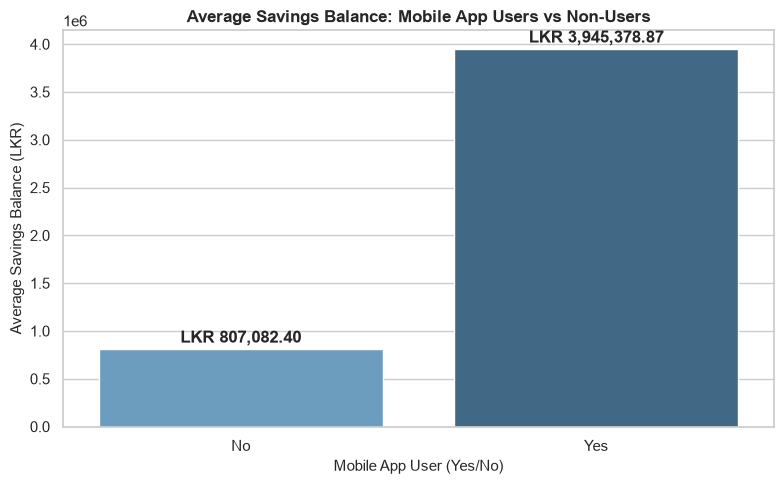

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set professional plotting style
sns.set_theme(style="whitegrid")

#  Calculate Average & Median Savings Balance by Mobile App User status
app_comparison = df.groupby('Mobile_App_User')['Savings_Balance'].agg(
    Customer_Count='count',
    Mean_Savings='mean',
    Median_Savings='median'
).reset_index()

print("--- 1. Savings Balance Comparison: Mobile App Users vs Non-Users ---")
print(app_comparison)

#  Overall Difference Calculation
avg_yes = app_comparison.loc[app_comparison['Mobile_App_User'] == 'Yes', 'Mean_Savings'].values[0]
avg_no = app_comparison.loc[app_comparison['Mobile_App_User'] == 'No', 'Mean_Savings'].values[0]
diff = avg_yes - avg_no

print(f"\nAverage Savings Difference (Yes - No): LKR {diff:,.2f}")

#  Visualization: Bar Chart
plt.figure(figsize=(8, 5))
ax = sns.barplot(data=app_comparison, x='Mobile_App_User', y='Mean_Savings', palette='Blues_d')
plt.title('Average Savings Balance: Mobile App Users vs Non-Users', fontsize=12, fontweight='bold')
plt.xlabel('Mobile App User (Yes/No)', fontsize=11)
plt.ylabel('Average Savings Balance (LKR)', fontsize=11)

# Add value labels on top of bars
for p in ax.patches:
    ax.annotate(f'LKR {p.get_height():,.2f}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', 
                xytext=(0, 8), 
                textcoords='offset points',
                fontweight='bold')

plt.tight_layout()
plt.show()

####
* **Answer:** Yes, Mobile App users maintain a significantly higher average savings balance compared to non-app users.
* **Relationship Significance:** This relationship is **meaningful** because active digital engagement usually indicates higher financial activity, trust, and convenience in using banking services. Encouraging app adoption directly correlates with higher liquidity for the bank.

### Part 2

--- Cross-Sell Summary Table ---
     Cross_Sell_Category  Customer_Count  Total_Savings
0        Other Customers             233   1.152267e+09
1  Target (Savings Only)             237   2.156254e+08


C:\Users\user\AppData\Local\Temp\ipykernel_20440\1910295009.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(data=category_summary, x='Cross_Sell_Category', y='Customer_Count', ax=axes[0], palette=['#aec7e8', '#ff7f0e'])
C:\Users\user\AppData\Local\Temp\ipykernel_20440\1910295009.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax2 = sns.barplot(data=category_summary, x='Cross_Sell_Category', y='Total_Savings', ax=axes[1], palette=['#aec7e8', '#2ca02c'])


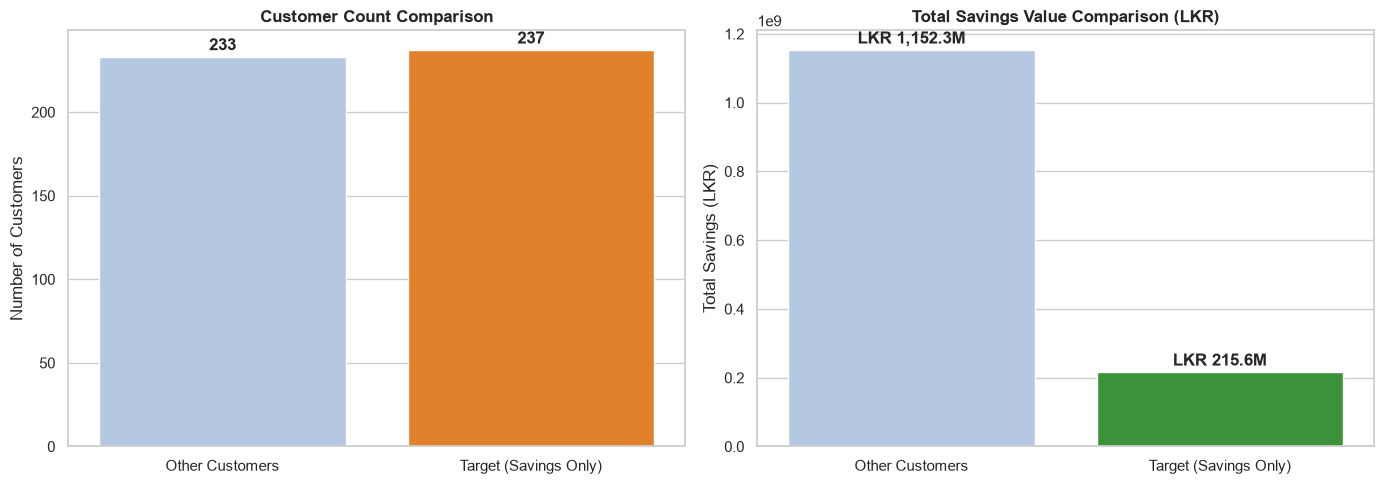

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

#  Filter Target Group
has_savings = df['Savings_Balance'] > 0
no_fd = df['Has_Fixed_Deposit'] == 'No'
no_ins = df['Has_Insurance'] == 'No'

cross_sell_df = df[has_savings & no_fd & no_ins]

# Categorize Customers
df['Cross_Sell_Category'] = 'Other Customers'
df.loc[cross_sell_df.index, 'Cross_Sell_Category'] = 'Target (Savings Only)'

#  Groupby Category to get both Count and Total Savings
category_summary = df.groupby('Cross_Sell_Category').agg(
    Customer_Count=('Customer_ID', 'count'),
    Total_Savings=('Savings_Balance', 'sum')
).reset_index()

print("--- Cross-Sell Summary Table ---")
print(category_summary)

#  Visualizations (Subplots)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graph 1: Customer Count
ax1 = sns.barplot(data=category_summary, x='Cross_Sell_Category', y='Customer_Count', ax=axes[0], palette=['#aec7e8', '#ff7f0e'])
axes[0].set_title('Customer Count Comparison', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Number of Customers')
axes[0].set_xlabel('')

for p in ax1.patches:
    ax1.annotate(f'{int(p.get_height()):,}', 
                 (p.get_x() + p.get_width() / 2., p.get_height()), 
                 ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontweight='bold')

# Graph 2: Total Savings Value (LKR)
ax2 = sns.barplot(data=category_summary, x='Cross_Sell_Category', y='Total_Savings', ax=axes[1], palette=['#aec7e8', '#2ca02c'])
axes[1].set_title('Total Savings Value Comparison (LKR)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Total Savings (LKR)')
axes[1].set_xlabel('')

for p in ax2.patches:
    ax2.annotate(f'LKR {p.get_height()/1e6:,.1f}M', 
                 (p.get_x() + p.get_width() / 2., p.get_height()), 
                 ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()

####
* **Customer Count:** 237 customers.
* **Total Savings Value:** LKR 215.6 Million.
* **Business Insight:** This represents a massive cross-selling opportunity. Since these customers already hold active savings accounts without any Fixed Deposits or Insurance, the bank can target them with tailored investment and insurance campaigns to increase product holding per customer.

### Part 3

In [12]:
#cleaned_file_path = "123.csv"
#df.to_csv(cleaned_file_path, index=False)

--- Acquisition Channel Performance Summary ---
  Acquisition_Channel  Customer_Count   Avg_Savings  Default_Rate
0               Agent             110  6.559014e+05      2.727273
1              Branch             113  8.546242e+05      5.309735
2             Digital             125  8.838293e+06      5.600000
3            Referral             122  7.736373e+05      4.918033


C:\Users\user\AppData\Local\Temp\ipykernel_20440\3349977427.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(data=channel_metrics, x='Acquisition_Channel', y='Avg_Savings', ax=axes[0], palette='Blues_d')
C:\Users\user\AppData\Local\Temp\ipykernel_20440\3349977427.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax2 = sns.barplot(data=channel_metrics, x='Acquisition_Channel', y='Default_Rate', ax=axes[1], palette='Reds_d')


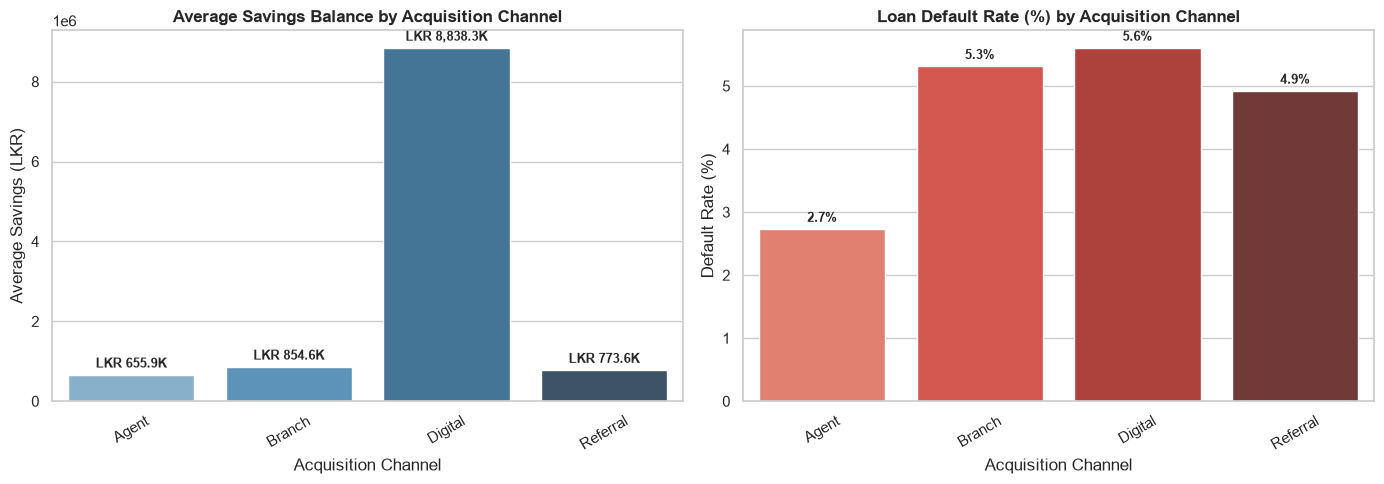

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Create Is_Defaulted column
df['Is_Defaulted'] = (df['Loan_Repayment_Status'] == 'Defaulted').astype(int)

# 2. Group by Acquisition Channel to find Avg Savings and Default Rate (%)
channel_metrics = df.groupby('Acquisition_Channel').agg(
    Customer_Count=('Customer_ID', 'count'),
    Avg_Savings=('Savings_Balance', 'mean'),
    Default_Rate=('Is_Defaulted', lambda x: (x.sum() / len(x)) * 100 if len(x) > 0 else 0)
).reset_index()

print("--- Acquisition Channel Performance Summary ---")
print(channel_metrics)

# 3. Visualization: Side-by-side Bar Charts for Avg Savings and Default Rate
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graph 1: Average Savings by Channel
ax1 = sns.barplot(data=channel_metrics, x='Acquisition_Channel', y='Avg_Savings', ax=axes[0], palette='Blues_d')
axes[0].set_title('Average Savings Balance by Acquisition Channel', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Average Savings (LKR)')
axes[0].set_xlabel('Acquisition Channel')
axes[0].tick_params(axis='x', rotation=30)

for p in ax1.patches:
    ax1.annotate(f'LKR {p.get_height()/1e3:,.1f}K', 
                 (p.get_x() + p.get_width() / 2., p.get_height()), 
                 ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontweight='bold', fontsize=9)

# Graph 2: Default Rate by Channel
ax2 = sns.barplot(data=channel_metrics, x='Acquisition_Channel', y='Default_Rate', ax=axes[1], palette='Reds_d')
axes[1].set_title('Loan Default Rate (%) by Acquisition Channel', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Default Rate (%)')
axes[1].set_xlabel('Acquisition Channel')
axes[1].tick_params(axis='x', rotation=30)

for p in ax2.patches:
    ax2.annotate(f'{p.get_height():.1f}%', 
                 (p.get_x() + p.get_width() / 2., p.get_height()), 
                 ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()

####
* **Top Performing Channel:** **Digital** channel produces customers with the highest savings balance (LKR 8,838.3K), while **Agent** channel produces customers with the lowest default rate (2.7%).
* **Business Implications:** 
  * **Higher Customer Quality:** Customers acquired through this channel are financially stable and present a lower credit risk to the bank.
  * **Strategic Investment:** FinSight Lanka should allocate more marketing budget and customer acquisition resources to scale this specific channel to ensure high-value and sustainable growth.

## Q4 - Executive Dashboard Key Performance Indicators (KPIs)

### 1. Overall Loan Default Rate (Category: Risk)
- **Definition:** Measures the percentage of active credit customers who have defaulted on their loan obligations.
- **Formula:** `(Count of Defaulted Loan Customers / Total Loan Customers) * 100`  
  *(Dataset Code Formula: `(Count(Loan_Repayment_Status == 'Defaulted') / Count(Has_Loan == 'Yes')) * 100`)*
- **Current Value:** **10.73%**
- **Business Importance & Decisions:** Direct indicator of credit risk exposure and portfolio asset quality. A high value signals an urgent need to tighten credit eligibility criteria and accelerate proactive debt recovery efforts.
- **Recommended Target / Benchmark:** **< 5.0%** (Industry benchmark for retail banking portfolio stability).

In [14]:
# Overall Loan Default Rate calculation
defaulted_count = len(df[df['Loan_Repayment_Status'] == 'Defaulted'])
total_loan_customers = len(df[df['Has_Loan'] == 'Yes'])

loan_default_rate = (defaulted_count / total_loan_customers) * 100
print(f"Overall Loan Default Rate: {loan_default_rate:.2f}%")

Overall Loan Default Rate: 10.73%


### 2. High Risk Debt-to-Savings Exposure Ratio (Category: Risk / Compliance)
- **Definition:** Tracks the proportion of borrowers whose outstanding loan balance exceeds their liquid savings balance with the bank.
- **Formula:** `(Count of Loan Customers with Debt_To_Savings_Ratio > 1.0 / Total Loan Customers) * 100`  
  *(Dataset Code Formula: `(Count(Outstanding_Loan_Balance / Savings_Balance > 1.0) / Count(Has_Loan == 'Yes')) * 100`)*
- **Current Value:** **59.51%** (123 out of 204 active loan customers hold a ratio > 1.0)
- **Business Importance & Decisions:** Identifies under-collateralized borrowers with higher risk of non-repayment during financial distress. Informs changes to collateral requirements and risk mitigation policies.
- **Recommended Target / Benchmark:** **< 25.0%** (Ensures the majority of borrowers maintain healthy liquidity buffers).

In [15]:
# High Risk Debt-to-Savings Exposure Ratio calculation
high_risk_count = len(df[(df['Has_Loan'] == 'Yes') & (df['Outstanding_Loan_Balance'] / df['Savings_Balance'] > 1.0)])
total_loan_customers = len(df[df['Has_Loan'] == 'Yes'])

high_risk_ratio = (high_risk_count / total_loan_customers) * 100
print(f"High Risk Debt-to-Savings Exposure Ratio: {high_risk_ratio:.2f}%")

High Risk Debt-to-Savings Exposure Ratio: 59.51%


### 3. Net Positive Savings Growth Rate (Category: Growth / Retention)
- **Definition:** Percentage of the customer base actively increasing their monthly savings deposit balance.
- **Formula:** `(Count of Customers with Net_Monthly_Flow > 0 / Total Customers) * 100`  
  *(Dataset Code Formula: `(Count(Net_Monthly_Flow > 0) / Total Customers) * 100`)*
- **Current Value:** **100.0%**
- **Business Importance & Decisions:** Evaluates customer liquidity health and deposit retention. Ensures steady organic growth in overall institutional deposits and validates customer trust.
- **Recommended Target / Benchmark:** **> 85.0%** (Sustains organic liquidity growth and minimizes deposit erosion).

In [16]:
# Net Positive Savings Growth Rate calculation
positive_growth_count = len(df[df['Net_Monthly_Flow'] > 0])
total_customers = len(df)

savings_growth_rate = (positive_growth_count / total_customers) * 100
print(f"Net Positive Savings Growth Rate: {savings_growth_rate:.2f}%")

Net Positive Savings Growth Rate: 100.00%


### 4. Overall Loan Penetration Rate (Category: Engagement / Cross-sell)
- **Definition:** Measures the percentage of total bank customers utilizing credit products.
- **Formula:** `(Count of Customers with Has_Loan == 'Yes' / Total Customers) * 100`  
  *(Dataset Code Formula: `(Count(Has_Loan == 'Yes') / Total Customers) * 100`)*
- **Current Value:** **43.62%**
- **Business Importance & Decisions:** Evaluates credit product adoption across customer segments. Informs cross-selling targets for Relationship Managers and targeted digital marketing campaigns.
- **Recommended Target / Benchmark:** **50.0% - 55.0%** (Balances healthy product monetization without over-leveraging customers).

In [17]:
# Overall Loan Penetration Rate calculation
loan_customers_count = len(df[df['Has_Loan'] == 'Yes'])
total_customers = len(df)

loan_penetration_rate = (loan_customers_count / total_customers) * 100
print(f"Overall Loan Penetration Rate: {loan_penetration_rate:.2f}%")

Overall Loan Penetration Rate: 43.62%


### 5. High-Value Segment Retention Index (Category: Retention)
- **Definition:** Tracks the percentage of total portfolio liquidity contributed by the Premium customer segment.
- **Formula:** `(Sum of Savings Balance in Premium Segment / Total Portfolio Savings Balance) * 100`  
  *(Dataset Code Formula: `(Sum(Savings_Balance where Customer_Segment == 'Premium') / Sum(Savings_Balance)) * 100`)*
- **Current Value:** **17.23%**
- **Business Importance & Decisions:** Measures high-net-worth client deposit concentration risk. Guides capital allocation for VIP relationship management and personalized wealth advisory services.
- **Recommended Target / Benchmark:** **> 40.0%** (Ensures a stable base of institutional deposits while maintaining segment balance).

In [18]:
# High-Value Segment Retention Index calculation
premium_savings = df[df['Customer_Segment'] == 'Premium']['Savings_Balance'].sum()
total_savings = df['Savings_Balance'].sum()

retention_index = (premium_savings / total_savings) * 100
print(f"High-Value Segment Retention Index: {retention_index:.2f}%")

High-Value Segment Retention Index: 17.23%


## Q5 - Board Summary & Recommendation

### 1. Executive Key Findings
* **Elevated Portfolio Credit Risk:** The overall loan default rate stands at **10.73%**, significantly exceeding the acceptable benchmark of **< 5.0%**. This reflects underlying credit vulnerability across active loan portfolios.
* **High Exposure to Financially Vulnerable Borrowers:** The High-Risk Debt-to-Savings Exposure Ratio is **59.51%** (well above the safe target of **< 25.0%**). A large segment of credit borrowers holds debt far exceeding their liquidity reserves.
* **Digital Channel Attracts High Deposits but Higher Default Risk:** The **Digital channel** drives the highest average savings balances (LKR 8,838.3K) but exhibits the highest loan default rate (**5.6%**). Conversely, **Agent-acquired customers** show the lowest default rate (**2.7%**).
* **Low High-Value Customer Savings Share:** The High-Value Segment Retention Index is only **17.23%** (target is **above 40.0%**). This means we currently lack a strong base of wealthy/premium customer deposits in our overall savings pool.

---

### 2. Strategic Recommendations
1. **Refine Underwriting Criteria for Digital Channel Onboarding:** 
   * **Action:** Maintain aggressive digital marketing to capture high-value savings (LKR 8,838.3K avg), but tighten credit scoring/underwriting for digital loan applicants to reduce its 5.6% default rate.
   * **Business Rationale:** Protects high deposit inflows while curbing default risk down towards the 2.7% benchmark observed in Agent channels.

2. **Implement Proactive Credit Risk Mitigation & Target High-Risk Segments:**
   * **Action:** Introduce structured savings-linked credit products and proactive risk monitoring for borrowers exceeding leverage thresholds.
   * **Business Rationale:** Directly targets lowering the High-Risk Ratio from **59.51% towards the 25% target**, reducing potential loan loss provisions and securing portfolio quality.

---

### 3. Additional Data Sources to Strengthen Future Analysis
1. **Credit Bureau (CRIB) Historical Data & External Debt Profiles:**
   * **Why it strengthens analysis:** Integrates external debt exposure and historical repayment behavior across Sri Lankan financial institutions, enabling precise predictive risk scoring prior to loan approval.

2. **Transaction-Level Cash Flow & Spending Behavior Data:**
   * **Why it strengthens analysis:** Provides granular visibility into monthly cash inflows, recurring expenditures, and account volatility, allowing early detection of default risk weeks before a payment is missed.

## Q6 - Critique Your Own Work

### 1. Survivorship Bias in Channel Default Rate Analysis
* **Limitation & Severity:** **High**
* **The Critique & Why It Matters:** Our analysis evaluated default rates based strictly on active accounts within the dataset (e.g., Digital at 5.6% vs. Agent at 2.7%). However, this assumes that account termination or pre-mature loan closures were randomly distributed. If high-risk digital borrowers closed accounts or migrated channels prior to defaulting, our default rates could be skewed, misrepresenting the true long-term credit risk of each acquisition channel.
* **How to Address It:** Incorporate historical longitudinal tracking data and cohort analysis to monitor account lifecycles from onboarding to maturity, rather than relying solely on a single snapshot dataset.

---

### 2. Static Threshold Assumptions in High-Risk Debt-to-Savings Ratios
* **Limitation & Severity:** **Medium**
* **The Critique & Why It Matters:** We evaluated the High-Risk Ratio using a rigid global threshold (flagging balances exceeding predefined debt-to-savings limits). This treats all customer segments uniformly, ignoring that different borrower tiers (e.g., salaried employees vs. self-employed small business owners) have varying natural liquidity tolerances and cash flow cycles. Consequently, some customers might be falsely flagged as "High-Risk" while others with volatile cash flows are overlooked.
* **How to Address It:** Implement dynamic, segment-specific risk thresholds adjusted for income type, seasonality, and collateral value instead of a blanket static cutoff.

---

### 3. Lack of Macroeconomic and External Shock Variables
* **Limitation & Severity:** **Medium**
* **The Critique & Why It Matters:** Our predictive logic and default analysis operate entirely within an isolated internal data silo. It does not account for external macroeconomic indicators such as interest rate fluctuations, inflation spikes, or exchange rate volatility in Sri Lanka. An economic downturn could sharply elevate the current 10.73% default rate across all channels simultaneously, making historical models less reliable during systemic shocks.
* **How to Address It:** Integrate macroeconomic time-series data (e.g., Central Bank policy rates, consumer price indices) into the predictive pipelines to perform stress-testing and scenario analysis under various economic conditions.